In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = "/content/drive/MyDrive/world_model_probe"
for d in ["environment", "data", "model", "interpretability", "results"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
open(f"{ROOT}/environment/__init__.py", "w").close()
os.chdir(ROOT)
print(os.getcwd())

Mounted at /content/drive
/content/drive/MyDrive/world_model_probe


In [11]:
%%writefile /content/drive/MyDrive/world_model_probe/environment/gridworld.py
import numpy as np

S = 5          # grid size
T = 20         # moves per trajectory
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}   # UP, DOWN, LEFT, RIGHT
NAMES = ["UP", "DOWN", "LEFT", "RIGHT"]
VOCAB = 4 + S * S      # 4 actions + 25 start cells = 29


def valid_moves(r, c):
    return [a for a, (dr, dc) in ACTIONS.items()
            if 0 <= r + dr < S and 0 <= c + dc < S]


def make_traj(rng):
    r, c = rng.integers(S), rng.integers(S)
    tokens = [4 + r * S + c]
    pos = [(r, c)]
    for _ in range(T):
        a = rng.choice(valid_moves(r, c))
        dr, dc = ACTIONS[a]
        r, c = r + dr, c + dc
        tokens.append(a)
        pos.append((r, c))
    return tokens, pos


def generate_dataset(N=30000, seed=0):
    rng = np.random.default_rng(seed)
    seen, X, P = set(), [], []
    while len(X) < N:
        t, p = make_traj(rng)
        if tuple(t) in seen:
            continue
        seen.add(tuple(t))
        X.append(t)
        P.append(p)
    return np.array(X), np.array(P)


def split(X, P, tr=0.8, va=0.1):
    n_tr, n_va = int(tr * len(X)), int(va * len(X))
    return {
        "X_train": X[:n_tr],            "P_train": P[:n_tr],
        "X_val":   X[n_tr:n_tr + n_va], "P_val":   P[n_tr:n_tr + n_va],
        "X_test":  X[n_tr + n_va:],     "P_test":  P[n_tr + n_va:],
    }

Overwriting /content/drive/MyDrive/world_model_probe/environment/gridworld.py


In [12]:
import sys, numpy as np
sys.path.append(ROOT)
from environment.gridworld import *

X, P = generate_dataset(N=30000, seed=0)
np.savez(f"{ROOT}/data/data.npz", **split(X, P))

print("tokens:", X[0][:8])
print("decoded:", [f"START{tuple(map(int, P[0][0]))}"] + [NAMES[a] for a in X[0][1:8]])
print("positions:", [tuple(map(int, p)) for p in P[0][:8]])
print(X.shape, P.shape)

tokens: [27  2  0  1  0  0  0  0]
decoded: ['START(4, 3)', 'LEFT', 'UP', 'DOWN', 'UP', 'UP', 'UP', 'UP']
positions: [(4, 3), (4, 2), (3, 2), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2)]
(30000, 21) (30000, 21, 2)


**MODEL**

In [13]:
%%writefile /content/drive/MyDrive/world_model_probe/model/transformer.py
import torch
import torch.nn as nn


class Block(nn.Module):
    def __init__(self, d, heads, ff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Linear(ff, d))

    def forward(self, x, mask):
        h = self.ln1(x)
        a, _ = self.attn(h, h, h, attn_mask=mask, need_weights=False)
        x = x + a                      # residual around attention
        x = x + self.mlp(self.ln2(x))  # residual around MLP
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab=29, d=64, heads=2, ff=128, layers=3, max_len=21):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList([Block(d, heads, ff) for _ in range(layers)])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)

    def forward(self, x, return_hidden=False):
        n = x.shape[1]
        # True = blocked, so each token can only look at earlier ones
        mask = torch.triu(torch.ones(n, n, dtype=torch.bool, device=x.device), diagonal=1)
        h = self.tok(x) + self.pos(torch.arange(n, device=x.device))
        hidden = [h]                   # saving every layer's output for probing later
        for b in self.blocks:
            h = b(h, mask)
            hidden.append(h)
        logits = self.head(self.ln_f(h))
        return (logits, hidden) if return_hidden else logits

Overwriting /content/drive/MyDrive/world_model_probe/model/transformer.py


**TRAIN**

In [14]:
import torch, torch.nn.functional as F
open(f"{ROOT}/model/__init__.py", "a").close()
from model.transformer import TinyGPT

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)                  # should say cuda

d = np.load(f"{ROOT}/data/data.npz")
Xtr = torch.tensor(d["X_train"]).to(dev)
Xva = torch.tensor(d["X_val"]).to(dev)

model = TinyGPT().to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

def loss_fn(X):
    # input is everything but the last token, target is everything shifted by one
    logits = model(X[:, :-1])
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), X[:, 1:].reshape(-1))

for epoch in range(15):
    perm = torch.randperm(len(Xtr), device=dev)
    for i in range(0, len(Xtr), 256):
        loss = loss_fn(Xtr[perm[i:i+256]])
        opt.zero_grad()
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        val = loss_fn(Xva).item()
    model.train()
    print(f"epoch {epoch+1}  train {loss.item():.3f}  val {val:.3f}")

torch.save(model.state_dict(), f"{ROOT}/model/tinygpt.pt")

device: cpu
epoch 1  train 1.368  val 1.369
epoch 2  train 1.315  val 1.316
epoch 3  train 1.271  val 1.273
epoch 4  train 1.202  val 1.210
epoch 5  train 1.182  val 1.204
epoch 6  train 1.187  val 1.189
epoch 7  train 1.216  val 1.190
epoch 8  train 1.181  val 1.187
epoch 9  train 1.191  val 1.187
epoch 10  train 1.193  val 1.187
epoch 11  train 1.183  val 1.192
epoch 12  train 1.184  val 1.186
epoch 13  train 1.186  val 1.187
epoch 14  train 1.180  val 1.188
epoch 15  train 1.183  val 1.186


**did it learn anything about the grid**

In [15]:
Xte = torch.tensor(d["X_test"]).to(dev)
Pte = d["P_test"]

model.eval()
with torch.no_grad():
    pred = model(Xte[:, :-1])[:, :, :4].argmax(-1).cpu().numpy()   # best action at each step

cur = Pte[:, :-1]                                  # true position before each move
delta = np.array([ACTIONS[a] for a in range(4)])
new = cur + delta[pred]                            # where the predicted move would land
legal = ((new >= 0) & (new < S)).all(-1)
print("legal move rate:", legal.mean())

legal move rate: 1.0


**grab hidden states and train one probe per layer**

In [16]:
import torch.nn as nn

# run the model and keep each layer's hidden vectors
def get_hidden(X):
    model.eval()
    with torch.no_grad():
        _, hid = model(X, return_hidden=True)
    return [h.cpu() for h in hid]          # 4 items (embed, L1, L2, L3), each (N, 21, 64)

# 10k train trajectories is plenty for a linear probe
Xp = torch.tensor(d["X_train"][:10000]).to(dev)
H_tr = get_hidden(Xp)
H_te = get_hidden(Xte)

# label = which of the 25 cells the agent is in
def cell_label(P):
    return torch.tensor(P[..., 0] * S + P[..., 1]).reshape(-1)

y_tr = cell_label(d["P_train"][:10000]).to(dev)
y_te = cell_label(Pte).to(dev)

def run_probe(layer):
    xtr = H_tr[layer].reshape(-1, 64).to(dev)
    xte = H_te[layer].reshape(-1, 64).to(dev)
    lin = nn.Linear(64, 25).to(dev)        # the probe is just one linear layer
    opt = torch.optim.Adam(lin.parameters(), lr=1e-2)
    for step in range(500):                # full batch, it's small enough
        loss = F.cross_entropy(lin(xtr), y_tr)
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        return (lin(xte).argmax(-1) == y_te).float().mean().item()

names = ["embedding", "layer 1", "layer 2", "layer 3"]
accs = []
for i, n in enumerate(names):
    accs.append(run_probe(i))
    print(f"{n}: {accs[-1]:.3f}")
print("chance:", 1 / 25)

embedding: 0.098
layer 1: 0.431
layer 2: 0.968
layer 3: 0.892
chance: 0.04


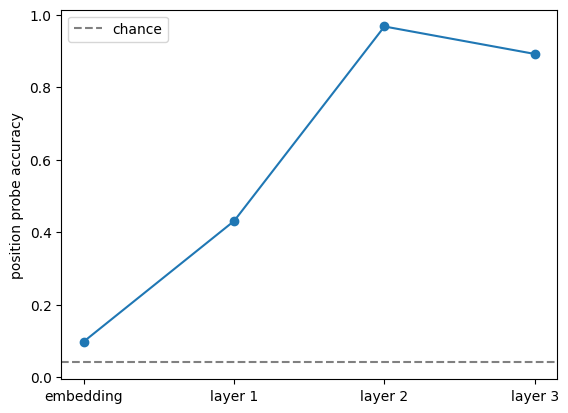

In [17]:
import matplotlib.pyplot as plt

plt.plot(names, accs, marker="o")
plt.axhline(1 / 25, color="gray", linestyle="--", label="chance")
plt.ylabel("position probe accuracy")
plt.legend()
plt.savefig(f"{ROOT}/results/probe_by_layer.png", dpi=150)
plt.show()

**control with an untrained model**

In [18]:
# same architecture, never trained
torch.manual_seed(0)
trained = model
model = TinyGPT().to(dev)

H_tr = get_hidden(Xp)
H_te = get_hidden(Xte)
rand_accs = [run_probe(i) for i in range(4)]
for n, a in zip(names, rand_accs):
    print(f"random {n}: {a:.3f}")

# put the trained model back, since run_probe reads these globals
model = trained
H_tr = get_hidden(Xp)
H_te = get_hidden(Xte)

random embedding: 0.098
random layer 1: 0.186
random layer 2: 0.194
random layer 3: 0.198


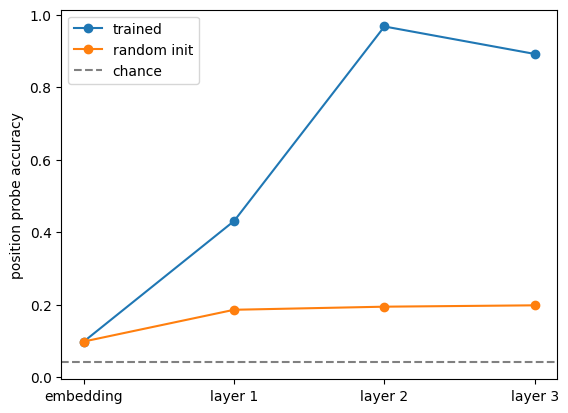

In [19]:
plt.plot(names, accs, marker="o", label="trained")
plt.plot(names, rand_accs, marker="o", label="random init")
plt.axhline(1 / 25, color="gray", linestyle="--", label="chance")
plt.ylabel("position probe accuracy")
plt.legend()
plt.savefig(f"{ROOT}/results/probe_trained_vs_random.png", dpi=150)
plt.show()

**similarity of same-cell vs different-cell trajectories**

This compares each trajectory’s hidden vector at the last token. Everyone is at the same time step there, so positional embeddings don’t muddy the comparison. Trajectories ending in the same cell almost always took different paths, so this matches your Path A / Path B idea.

I subtract the mean vector first. Otherwise every pair looks similar because of a shared offset in the activations.

In [20]:
# cosine similarity between last-token vectors, grouped by final cell
def sim_scores(H):
    cell = torch.tensor(Pte[:, -1, 0] * S + Pte[:, -1, 1])
    same = cell[:, None] == cell[None, :]
    same.fill_diagonal_(False)                 # a vector is trivially similar to itself
    diff = cell[:, None] != cell[None, :]
    out = []
    for h in H:
        h = h[:, -1, :]                        # (3000, 64)
        h = h - h.mean(0)                      # remove the shared offset
        h = h / h.norm(dim=1, keepdim=True)
        sim = h @ h.T
        out.append((sim[same].mean().item(), sim[diff].mean().item()))
    return out

res_trained = sim_scores(H_te)

# same thing for the untrained model
torch.manual_seed(0)
model = TinyGPT().to(dev)
res_random = sim_scores(get_hidden(Xte))
model = trained                                # put the trained one back

for n, t, r in zip(names, res_trained, res_random):
    print(f"{n:10s} trained same {t[0]:.3f} diff {t[1]:.3f} | random same {r[0]:.3f} diff {r[1]:.3f}")

embedding  trained same 0.065 diff -0.003 | random same 0.072 diff 0.000
layer 1    trained same 0.135 diff -0.006 | random same 0.072 diff 0.001
layer 2    trained same 0.363 diff -0.011 | random same 0.072 diff 0.001
layer 3    trained same 0.572 diff 0.136 | random same 0.072 diff 0.001


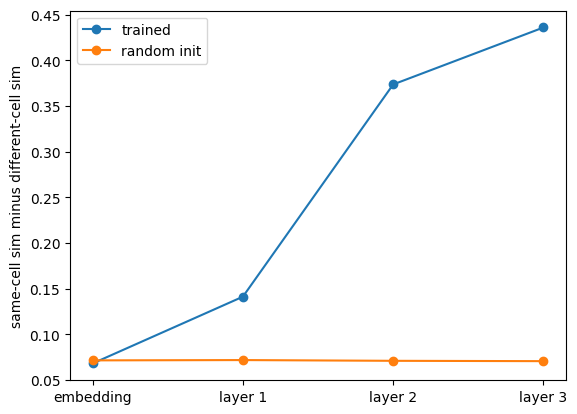

In [21]:
gap_t = [s - d for s, d in res_trained]
gap_r = [s - d for s, d in res_random]
plt.plot(names, gap_t, marker="o", label="trained")
plt.plot(names, gap_r, marker="o", label="random init")
plt.ylabel("same-cell sim minus different-cell sim")
plt.legend()
plt.savefig(f"{ROOT}/results/similarity_gap.png", dpi=150)
plt.show()

In [22]:
import json
out = {
    "probe_trained": accs,
    "probe_random": rand_accs,
    "sim_gap_trained": gap_t,
    "sim_gap_random": gap_r,
}
json.dump(out, open(f"{ROOT}/results/numbers.json", "w"), indent=2)

**layer 3 check, shuffled-label control, val loss, full similarity table**

In [ ]:
# same probe as before, but steps and labels can now be changed
def run_probe(layer, steps=500, labels=None):
    ytrain = y_tr if labels is None else labels
    xtr = H_tr[layer].reshape(-1, 64).to(dev)
    xte = H_te[layer].reshape(-1, 64).to(dev)
    lin = nn.Linear(64, 25).to(dev)
    opt = torch.optim.Adam(lin.parameters(), lr=1e-2)
    for step in range(steps):
        loss = F.cross_entropy(lin(xtr), ytrain)
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        return (lin(xte).argmax(-1) == y_te).float().mean().item()

# 1) longer probe training: does layer 3 recover?
accs_long = [run_probe(i, steps=1000) for i in range(4)]

# 2) shuffled labels: positions scrambled, so a good score would mean the probe is just memorizing
torch.manual_seed(0)
y_shuf = y_tr[torch.randperm(len(y_tr), device=dev)]
accs_shuf = [run_probe(i, steps=1000, labels=y_shuf) for i in range(4)]

print("layer      500 steps | 1000 steps | shuffled")
for n, a, b, c in zip(names, accs, accs_long, accs_shuf):
    print(f"{n:10s} {a:.3f}       {b:.3f}        {c:.3f}")

# 3) final val loss, to compare with the ~1.15-1.2 floor
model.eval()
with torch.no_grad():
    print("val loss:", loss_fn(Xva).item())

# 4) the full similarity table, including the rows that got cut off
for n, t, r in zip(names, res_trained, res_random):
    print(f"{n:10s} trained same {t[0]:.3f} diff {t[1]:.3f} | random same {r[0]:.3f} diff {r[1]:.3f}")

# **Rebuild from runtime reconnection**

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F

ROOT = "/content/drive/MyDrive/world_model_probe"
os.chdir(ROOT)
sys.path.append(ROOT)

from environment.gridworld import *
from model.transformer import TinyGPT

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
print(os.listdir("data"), os.listdir("model"))   # expect data.npz and tinygpt.pt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cpu
['data.npz'] ['__init__.py', '__pycache__', 'transformer.py', 'tinygpt.pt']


In [9]:
d = np.load(f"{ROOT}/data/data.npz")
Xte = torch.tensor(d["X_test"]).to(dev)
Pte = d["P_test"]

# only 2000 trajectories for probe training, to keep CPU time down
NP = 2000
Xp = torch.tensor(d["X_train"][:NP]).to(dev)

# load the already-trained model from Drive, no retraining
model = TinyGPT().to(dev)
model.load_state_dict(torch.load(f"{ROOT}/model/tinygpt.pt", map_location=dev))
model.eval()

def get_hidden(m, X):
    with torch.no_grad():
        _, hid = m(X, return_hidden=True)
    return [h.cpu() for h in hid]

def cell_label(P):
    return torch.tensor(P[..., 0] * S + P[..., 1]).reshape(-1)

# these two must use the same NP, or the shapes won't match
y_tr = cell_label(d["P_train"][:NP]).to(dev)
y_te = cell_label(Pte).to(dev)

def run_probe(H_tr, H_te, layer, steps=500, labels=None):
    ytrain = y_tr if labels is None else labels
    xtr = H_tr[layer].reshape(-1, 64).to(dev)
    xte = H_te[layer].reshape(-1, 64).to(dev)
    lin = nn.Linear(64, 25).to(dev)        # the probe is one linear layer
    opt = torch.optim.Adam(lin.parameters(), lr=1e-2)
    for _ in range(steps):
        loss = F.cross_entropy(lin(xtr), ytrain)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (lin(xte).argmax(-1) == y_te).float().mean().item()

def sim_scores(H):
    cell = torch.tensor(Pte[:, -1, 0] * S + Pte[:, -1, 1])
    same = cell[:, None] == cell[None, :]
    same.fill_diagonal_(False)             # a vector is trivially similar to itself
    diff = cell[:, None] != cell[None, :]
    out = []
    for h in H:
        h = h[:, -1, :]
        h = h - h.mean(0)                  # remove the shared offset
        h = h / h.norm(dim=1, keepdim=True)
        sim = h @ h.T
        out.append((sim[same].mean().item(), sim[diff].mean().item()))
    return out

In [10]:
names = ["embedding", "layer 1", "layer 2", "layer 3"]
torch.manual_seed(0)                       # fixes probe starting weights

# trained model
H_tr, H_te = get_hidden(model, Xp), get_hidden(model, Xte)
accs      = [run_probe(H_tr, H_te, i, 500)  for i in range(4)]
accs_long = [run_probe(H_tr, H_te, i, 1000) for i in range(4)]
print("trained probes done")

# shuffled labels: scrambled positions, tested on the real ones
y_shuf = y_tr[torch.randperm(len(y_tr), device=dev)]
accs_shuf = [run_probe(H_tr, H_te, i, 1000, y_shuf) for i in range(4)]
print("shuffled probes done")

# untrained model, same seed as before
torch.manual_seed(0)
rnd = TinyGPT().to(dev).eval()
R_tr, R_te = get_hidden(rnd, Xp), get_hidden(rnd, Xte)
rand_accs = [run_probe(R_tr, R_te, i, 500) for i in range(4)]
print("untrained probes done")

# similarity (doesn't depend on probe settings)
res_trained = sim_scores(H_te)
res_random  = sim_scores(R_te)

print("\nlayer      trained500 trained1000 untrained500 shuffled1000")
for n, a, b, r, s in zip(names, accs, accs_long, rand_accs, accs_shuf):
    print(f"{n:10s} {a:.3f}      {b:.3f}       {r:.3f}        {s:.3f}")
print()
for n, t, r in zip(names, res_trained, res_random):
    print(f"{n:10s} trained same {t[0]:.3f} diff {t[1]:.3f} gap {t[0]-t[1]:.3f} | random gap {r[0]-r[1]:.3f}")

json.dump({
    "probe_trained_500": accs, "probe_trained_1000": accs_long,
    "probe_random_500": rand_accs, "probe_shuffled_1000": accs_shuf,
    "sim_trained": res_trained, "sim_random": res_random,
    "probe_train_trajectories": NP,
}, open(f"{ROOT}/results/numbers.json", "w"), indent=2)

trained probes done
shuffled probes done
untrained probes done

layer      trained500 trained1000 untrained500 shuffled1000
embedding  0.096      0.096       0.096        0.048
layer 1    0.432      0.473       0.181        0.050
layer 2    0.968      0.971       0.195        0.058
layer 3    0.901      0.929       0.198        0.052

embedding  trained same 0.065 diff -0.003 gap 0.068 | random gap 0.072
layer 1    trained same 0.135 diff -0.006 gap 0.141 | random gap 0.072
layer 2    trained same 0.363 diff -0.011 gap 0.374 | random gap 0.071
layer 3    trained same 0.572 diff 0.136 gap 0.436 | random gap 0.071


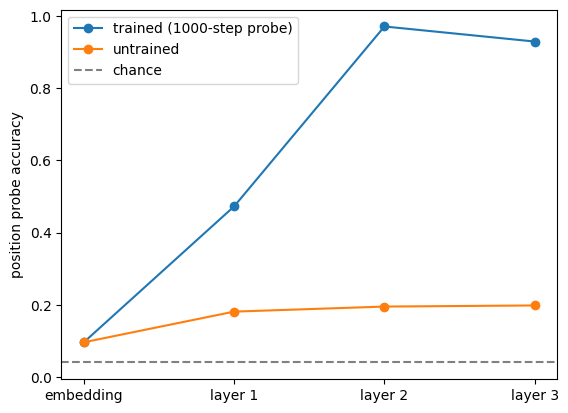

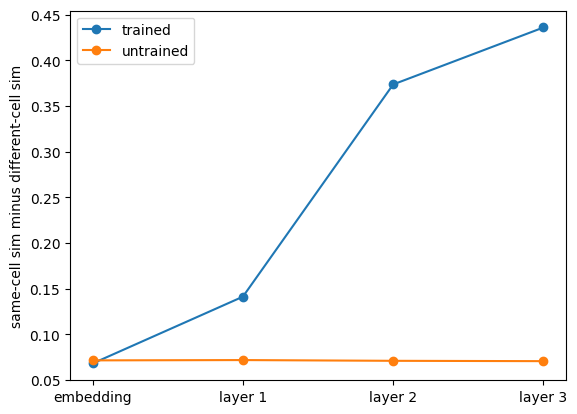

In [12]:
# probe accuracy, trained vs untrained
plt.plot(names, accs_long, marker="o", label="trained (1000-step probe)")
plt.plot(names, rand_accs, marker="o", label="untrained")
plt.axhline(1 / 25, color="gray", linestyle="--", label="chance")
plt.ylabel("position probe accuracy")
plt.legend()
plt.savefig(f"{ROOT}/results/probe_trained_vs_random.png", dpi=150)
plt.show()

# similarity gap
gap_t = [s - d for s, d in res_trained]
gap_r = [s - d for s, d in res_random]
plt.plot(names, gap_t, marker="o", label="trained")
plt.plot(names, gap_r, marker="o", label="untrained")
plt.ylabel("same-cell sim minus different-cell sim")
plt.legend()
plt.savefig(f"{ROOT}/results/similarity_gap.png", dpi=150)
plt.show()